# Análisis Exploratorio de Movilidad Telefónica

In [1]:
from pathlib import Path

import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Rutas del proyecto
PROJECT_ROOT = Path.cwd().resolve().parent
DATA_DIR = PROJECT_ROOT / "data" / "processed" / "telefonica"

# Archivo de movilidad entre municipios
M2_PATH = DATA_DIR / "M2.parquet"

# Comprobar que existe
print("Archivo M2 encontrado:", M2_PATH.is_file())
print("Ruta:", M2_PATH)


Archivo M2 encontrado: True
Ruta: C:\Users\marti\R-MOVE\data\processed\telefonica\M2.parquet


## 1. Introducción

In [2]:
con = duckdb.connect()

# Obtener información general del dataset
resumen_m2 = con.execute(
    """
    SELECT
        COUNT(*) AS registros,
        MIN(day) AS primera_fecha,
        MAX(day) AS ultima_fecha,
        COUNT(DISTINCT day) AS dias_disponibles,
        SUM(viajes) AS total_viajes
    FROM read_parquet(?)
    """,
    [str(M2_PATH)]
).df()

display(resumen_m2)

,registros,primera_fecha,ultima_fecha,dias_disponibles,total_viajes
0,64880151,2023-01-01,2025-08-31,971,3.686600e+09


## 2. Evolución temporal

,day,viajes
0,2023-01-01,2169439.0
1,2023-01-02,3465322.0
2,2023-01-03,3671647.0
3,2023-01-04,3917849.0
4,2023-01-05,3600172.0


Días analizados: 971


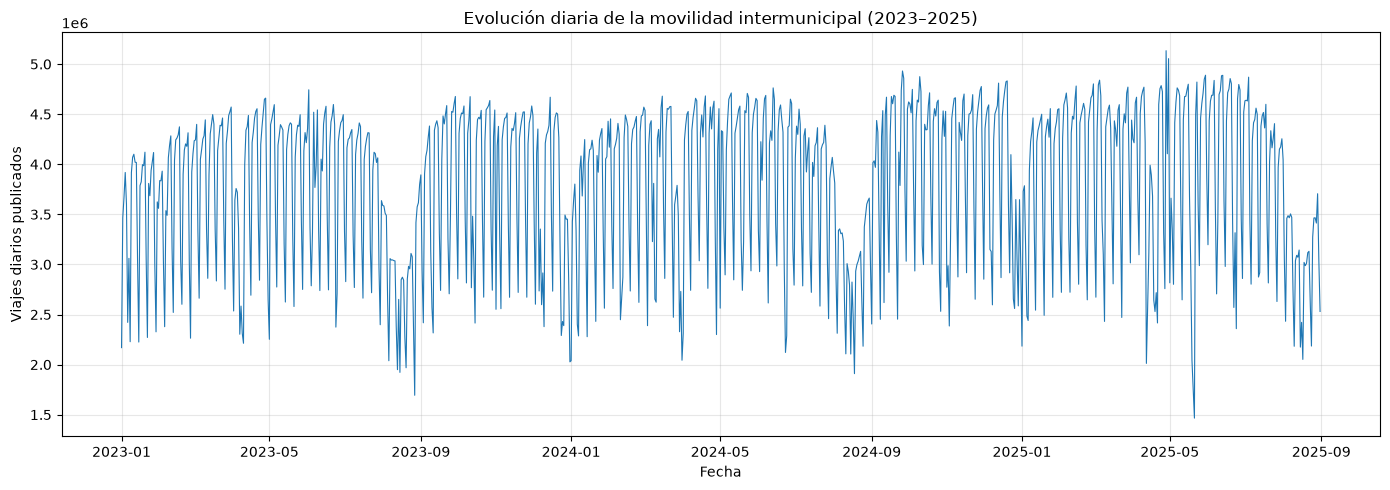

In [4]:
# Calcular el volumen total de viajes por día
movilidad_diaria = con.execute(
    """
    SELECT
        day,
        SUM(viajes) AS viajes
    FROM read_parquet(?)
    GROUP BY day
    ORDER BY day
    """,
    [str(M2_PATH)]
).df()

display(movilidad_diaria.head())

print("Días analizados:", len(movilidad_diaria))


plt.figure(figsize=(14, 5))

plt.plot(
    movilidad_diaria["day"],
    movilidad_diaria["viajes"],
    linewidth=0.8
)

plt.title("Evolución diaria de la movilidad intermunicipal (2023–2025)")
plt.xlabel("Fecha")
plt.ylabel("Viajes diarios publicados")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()



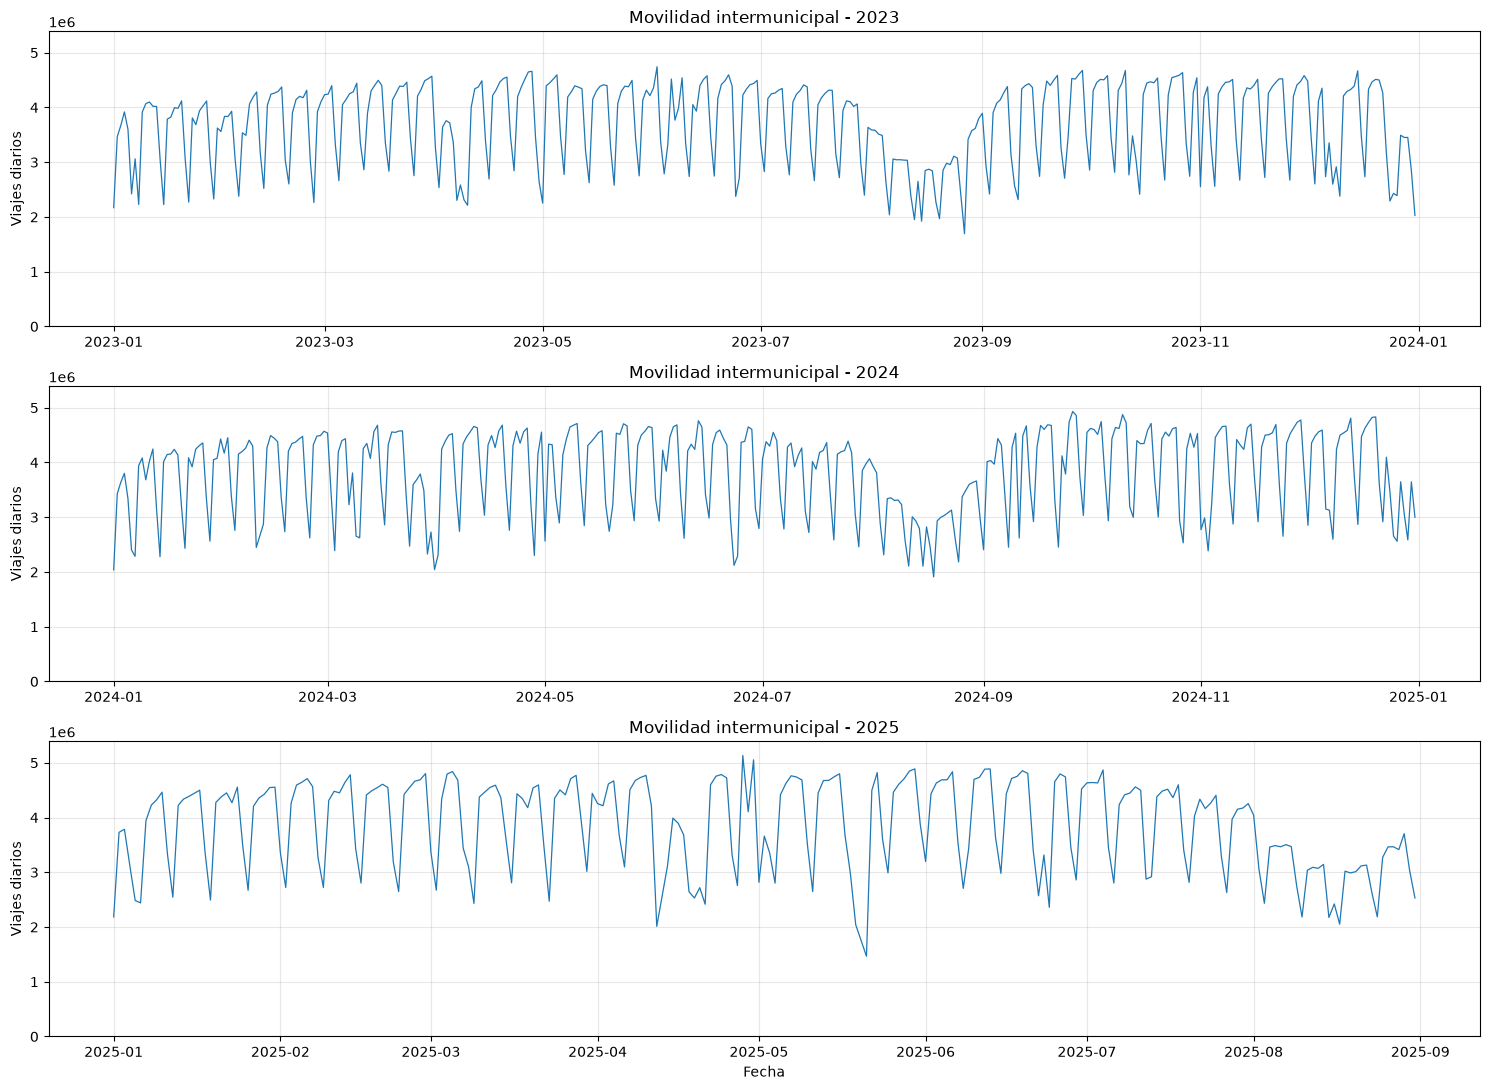

In [5]:

# Añadir el año a partir de la fecha
movilidad_diaria["año"] = movilidad_diaria["day"].dt.year

# Crear tres gráficos, uno para cada año
fig, axes = plt.subplots(3, 1, figsize=(15, 11))

# Misma escala vertical para facilitar la comparación
limite_y = movilidad_diaria["viajes"].max() * 1.05

for ax, año in zip(axes, [2023, 2024, 2025]):

    datos_año = movilidad_diaria[
        movilidad_diaria["año"] == año
    ]

    ax.plot(
        datos_año["day"],
        datos_año["viajes"],
        linewidth=0.9
    )

    ax.set_title(f"Movilidad intermunicipal - {año}")
    ax.set_ylabel("Viajes diarios")
    ax.set_ylim(0, limite_y)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Fecha")

plt.tight_layout()
plt.show()


In [6]:

estadisticas_diarias = movilidad_diaria["viajes"].describe()
display(estadisticas_diarias)


count    9.710000e+02
mean     3.796704e+06
std      7.847457e+05
min      1.465533e+06
25%      3.127009e+06
50%      4.112409e+06
75%      4.451290e+06
max      5.133535e+06
Name: viajes, dtype: float64

In [7]:

# Extraer el día de la semana
movilidad_diaria["dia_semana"] = movilidad_diaria["day"].dt.day_of_week

# Calcular estadísticas por día de la semana
patrones_semanales = (
    movilidad_diaria
    .groupby("dia_semana")["viajes"]
    .agg(["count", "mean", "median", "std"])
    .reset_index()
)

# Añadir nombres de los días
dias = {
    0: "Lunes",
    1: "Martes",
    2: "Miércoles",
    3: "Jueves",
    4: "Viernes",
    5: "Sábado",
    6: "Domingo"
}

patrones_semanales["dia"] = patrones_semanales["dia_semana"].map(dias)

display(
    patrones_semanales[
        ["dia", "count", "mean", "median", "std"]
    ]
)


,dia,count,mean,median,std
0,Lunes,139,3.899911e+06,4151639.0,621340.347010
1,Martes,138,4.162334e+06,4338277.5,511509.571819
2,Miércoles,139,4.163764e+06,4384373.0,599555.835040
3,Jueves,139,4.262562e+06,4445155.0,540223.878260
4,Viernes,139,4.244912e+06,4476912.0,621137.137777
5,Sábado,139,3.228881e+06,3332818.0,361607.007143
6,Domingo,138,2.608648e+06,2667416.0,279649.661177


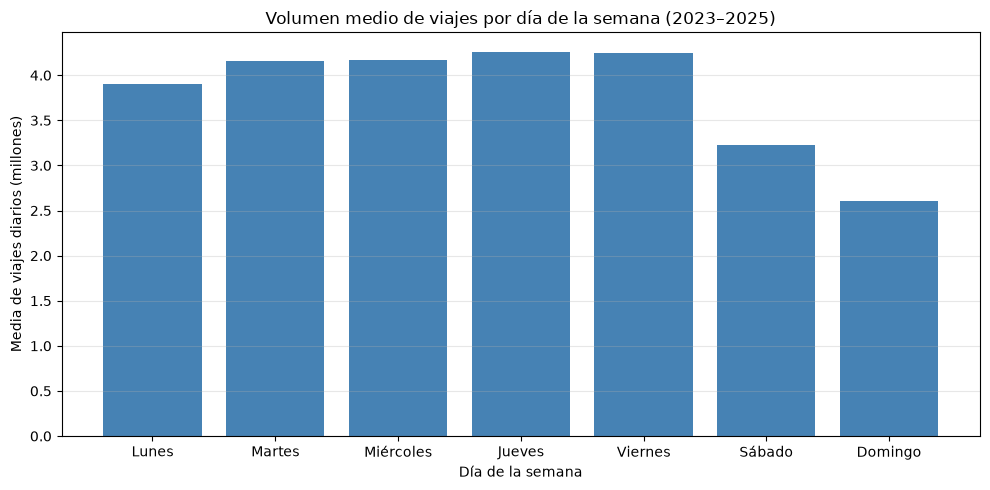

In [8]:

plt.figure(figsize=(10, 5))

plt.bar(
    patrones_semanales["dia"],
    patrones_semanales["mean"] / 1_000_000,
    color="steelblue"
)

plt.title("Volumen medio de viajes por día de la semana (2023–2025)")
plt.xlabel("Día de la semana")
plt.ylabel("Media de viajes diarios (millones)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()
